**Imports**

In [1]:
import pandas as pd                          #for dealing data in data frames
import numpy as np                           #for mathematical functions
import matplotlib.pyplot as plt              #for plotting

# Load the dataset
df = pd.read_csv("/kaggle/input/datasets/ezzaldeenesmail/obesitydataset-raw-and-data-sinthetic/ObesityDataSet_raw_and_data_sinthetic.csv")

# Display the first five rows
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


**Understanding Data**

In [2]:
print("Dataset shape:", df.shape)           #returns rows by columns

print("\nColumn names:")
print(df.columns.tolist())                 #turns number of cols to list 

print("\nDataset information:")
df.info()                                 #returns non-null count and data type

Dataset shape: (2111, 17)

Column names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-n

In [3]:
print(df["NObeyesdad"].value_counts())             #counts the occurence of categories

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


**Check Missing and Duplicate values**

In [7]:
print("Missing values:", df.isnull().sum().sum())        #checking missing values
print("Duplicate rows:", df.duplicated().sum())          #checking duplicates values and returns count of duplicated rows

Missing values: 0
Duplicate rows: 24


**Identify Categorical Columns**

In [9]:
# Select categorical columns
categorical_cols = df.drop(columns=["NObeyesdad"]).select_dtypes(include="object").columns.tolist()

print(categorical_cols)

['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


In [10]:
#for all categories in returns the distribution of categories in each column
for col in categorical_cols:
    print(f"\n{col}:")
    print("Number of categories:", df[col].nunique())
    print(df[col].value_counts())


Gender:
Number of categories: 2
Gender
Male      1068
Female    1043
Name: count, dtype: int64

family_history_with_overweight:
Number of categories: 2
family_history_with_overweight
yes    1726
no      385
Name: count, dtype: int64

FAVC:
Number of categories: 2
FAVC
yes    1866
no      245
Name: count, dtype: int64

CAEC:
Number of categories: 4
CAEC
Sometimes     1765
Frequently     242
Always          53
no              51
Name: count, dtype: int64

SMOKE:
Number of categories: 2
SMOKE
no     2067
yes      44
Name: count, dtype: int64

SCC:
Number of categories: 2
SCC
no     2015
yes      96
Name: count, dtype: int64

CALC:
Number of categories: 4
CALC
Sometimes     1401
no             639
Frequently      70
Always           1
Name: count, dtype: int64

MTRANS:
Number of categories: 5
MTRANS
Public_Transportation    1580
Automobile                457
Walking                    56
Motorbike                  11
Bike                        7
Name: count, dtype: int64


In [11]:
summary = pd.DataFrame({
    "Unique_Categories": df[categorical_cols].nunique(),       #returns unique categories
    "Categories": [
        df[col].unique().tolist()                              #convert those categories to list 
        for col in categorical_cols
    ]
})

summary

,Unique_Categories,Categories
Gender,2,"[Female, Male]"
family_history_with_overweight,2,"[yes, no]"
FAVC,2,"[no, yes]"
CAEC,4,"[Sometimes, Frequently, Always, no]"
SMOKE,2,"[no, yes]"
SCC,2,"[no, yes]"
CALC,4,"[no, Sometimes, Frequently, Always]"
MTRANS,5,"[Public_Transportation, Walking, Automobile, M..."


**Numerical Features Summary**

In [12]:
#pruning out columms whose data types are either integer or float(numeric columns)
numeric_cols = df.drop(columns=["NObeyesdad"]).select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

display(df[numeric_cols].describe().round(2))         #describing data using maths functions 

Numerical columns:
['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00
mean,24.31,1.70,86.59,2.42,2.69,2.01,1.01,0.66
std,6.35,0.09,26.19,0.53,0.78,0.61,0.85,0.61
min,14.00,1.45,39.00,1.00,1.00,1.00,0.00,0.00
25%,19.95,1.63,65.47,2.00,2.66,1.58,0.12,0.00
50%,22.78,1.70,83.00,2.39,3.00,2.00,1.00,0.63
75%,26.00,1.77,107.43,3.00,3.00,2.48,1.67,1.00
max,61.00,1.98,173.00,3.00,4.00,3.00,3.00,2.00


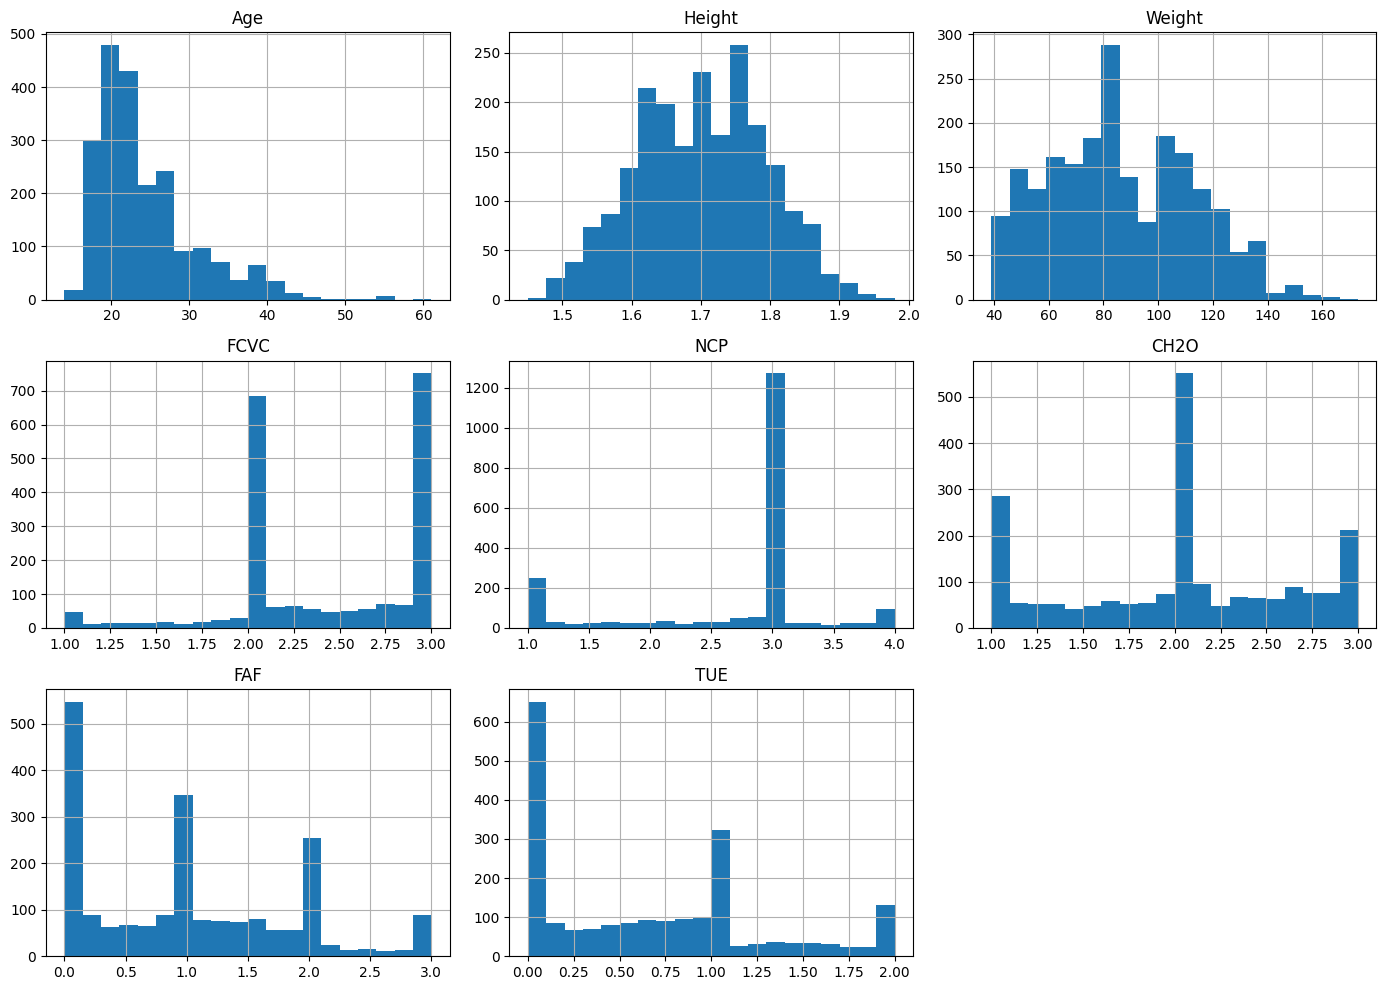

In [13]:
df[numeric_cols].hist(                        #creating histograms for all numeric cols
    figsize=(14, 10),                         #length by wide of histograms
    bins=20
)

plt.tight_layout()       #adjust spacing so no overlap occurs in mulitple plots
plt.show()                                    #showing the plot

**Checking Outliers in Numerical Features**

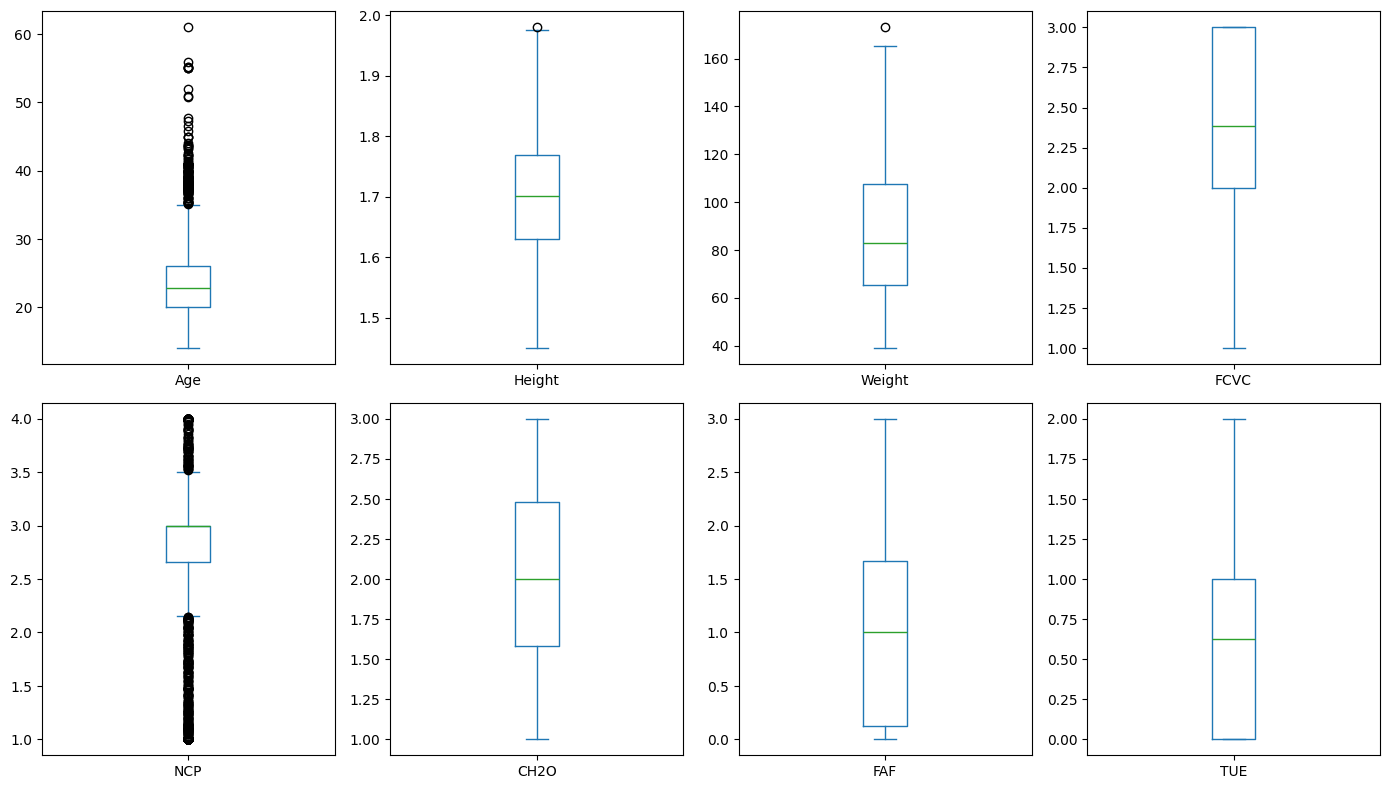

In [33]:
#it shows box plot where box means where most of data is present there, and discrete points show outliers

df[numeric_cols].plot(                  #plotting numeric cols
    kind="box",                       #box plot
    subplots=True,               
    layout=(2, 4),
    figsize=(14, 8),                   #length by width
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

**Check Target Class Distribution**

In [15]:
target_col = "NObeyesdad"              #target col which we are going to classify

print("Number of classes:", df[target_col].nunique())     #returns unique categories of target cols     

display(
    df[target_col]
    .value_counts()
    .to_frame(name="Count")
    .assign(
        Percentage=lambda x: (x["Count"] / len(df) * 100).round(2)
    )
)

Number of classes: 7


,Count,Percentage
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


**Separate Features and Target**

In [16]:
X = df.drop("NObeyesdad", axis=1)               #droping target cols
y = df["NObeyesdad"]                            #assigning target cols to a new df var

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2111, 16)
Target shape: (2111,)


**Test Train Split**

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,               #splitting target and train by 80 and 20
    random_state=42,
    shuffle=True,                #shuffle records in dataset
    stratify=y                    
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1688, 16)
X_test: (423, 16)
y_train: (1688,)
y_test: (423,)


**Import Preprocessing Tools**

In [18]:
from sklearn.compose import ColumnTransformer     #for performing operations on columns
from sklearn.pipeline import Pipeline             #for creating pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler        #for applying encoder to categorics cols and standard scaler to numeric cols

In [21]:
#preprocessing cols 
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),   #standard scaling to numeric features
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)   #one hot encoding to categoric cols
    ]
)

**Model Pipeline** 

In [22]:
#import models 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [23]:
#define models 
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1                             #for parallel tree formation
    ),

    "KNN": KNeighborsClassifier(),

    "SVM": SVC(),

}

print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM']


**Defining Grid Search Space**

In [24]:
#find best parameter for all models using gridsearch cv
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__solver": ["lbfgs"]
    },

    "Decision Tree": {
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 2]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7],
        "model__weights": ["uniform", "distance"]
    },

    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    },
}

print("Parameter grids defined:", len(param_grids))

Parameter grids defined: 5


In [25]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,                   #defining how CV will be done 
    shuffle=True,                 #shuffle CV split
    random_state=42
)

**Run GridSearchCV on all**

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
import pandas as pd

results = []
best_estimators = {}

for name, model in models.items():

    print(f"Training and tuning: {name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,                      
        param_grid=param_grids[name],             # for all parameters perform grid search
        scoring="f1_macro",                    #scoring formula to find best parameters
        cv=cv,
        n_jobs=-1,                      #parallel processing if possible
        refit=True,
        verbose=1
    )

    grid_search.fit(X_train, y_train)             #training models using give parameter grid

    best_estimators[name] = grid_search.best_estimator_     #selecting the best estimator from all

    results.append({                            #add results with name best score and parameter used for it
        "Model": name,
        "Best CV Macro F1": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

results_df = pd.DataFrame(results).sort_values(       #form df of result and sort by highest f1 score to lowest
    by="Best CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df)

Training and tuning: Logistic Regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Training and tuning: Decision Tree
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Training and tuning: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Training and tuning: KNN
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Training and tuning: SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits


,Model,Best CV Macro F1,Best Parameters
0,SVM,0.961881,"{'model__C': 10, 'model__kernel': 'linear'}"
1,Logistic Regression,0.936396,"{'model__C': 10, 'model__solver': 'lbfgs'}"
2,Random Forest,0.932315,"{'model__max_depth': 20, 'model__min_samples_l..."
3,Decision Tree,0.922436,"{'model__max_depth': None, 'model__min_samples..."
4,KNN,0.837069,"{'model__n_neighbors': 3, 'model__weights': 'd..."


**Evaluate all Models**

In [27]:
from sklearn.metrics import accuracy_score, f1_score

test_results = []

for name, model in best_estimators.items():
    y_pred = model.predict(X_test)           #for all models trained use them to predict on test data

    test_results.append({                     #append every models result on test data
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Test Weighted F1": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

test_results_df = pd.DataFrame(test_results).sort_values(  #show result df with highest score to lowest on test data
    by="Test Macro F1",
    ascending=False
).reset_index(drop=True)

display(test_results_df.round(4))

,Model,Test Accuracy,Test Macro F1,Test Weighted F1
0,SVM,0.9622,0.9616,0.9621
1,Random Forest,0.9385,0.9383,0.9397
2,Logistic Regression,0.9314,0.9294,0.9310
3,Decision Tree,0.9149,0.9133,0.9153
4,KNN,0.8700,0.8594,0.8628


In [40]:
from sklearn.metrics import classification_report  

best_model = best_estimators[results_df.iloc[0]["Model"]]           #we are saving it as best model

y_pred = best_model.predict(X_test)      #predicting using best model

print(results_df.iloc[0]["Model"], "-", results_df.iloc[0]["Best CV Macro F1"])

print(classification_report(y_test, y_pred))        

SVM - 0.9618809159722733
                     precision    recall  f1-score   support

Insufficient_Weight       0.96      1.00      0.98        54
      Normal_Weight       0.96      0.91      0.94        58
     Obesity_Type_I       0.97      0.96      0.96        70
    Obesity_Type_II       0.97      1.00      0.98        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.92      0.95      0.93        58
Overweight_Level_II       0.95      0.93      0.94        58

           accuracy                           0.96       423
          macro avg       0.96      0.96      0.96       423
       weighted avg       0.96      0.96      0.96       423



**Confusion Matrix**

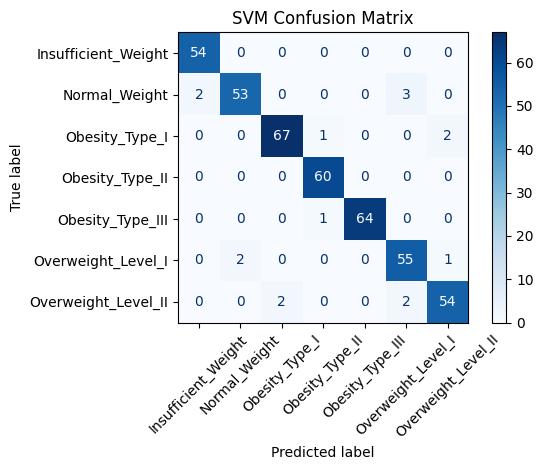

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

#displaying confusion matrix of SVM to find out how many test set problems it 
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

**Saving the Best Model**

In [30]:
#saving the model as pkl file 
import joblib

joblib.dump(best_model, "obesity_svm_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [42]:
import random

# pick a random row index from X_test
i = random.choice(X_test.index)

sample = X_test.loc[[i]]          # keep as DataFrame (pipeline expects 2-D)
actual = y_test.loc[i]            # true label
predicted = best_model.predict(sample)[0]

print("Sample:\n", sample.to_string())
print("\nActual label   :", actual)
print("Predicted label:", predicted)
print("Correct?       :", actual == predicted)

Sample:
       Gender        Age    Height     Weight family_history_with_overweight FAVC      FCVC  NCP       CAEC SMOKE      CH2O SCC       FAF       TUE CALC                 MTRANS
1138  Female  20.820455  1.547066  67.473282                            yes   no  2.303656  3.0  Sometimes    no  1.163111  no  1.926381  1.119877   no  Public_Transportation

Actual label   : Overweight_Level_II
Predicted label: Overweight_Level_II
Correct?       : True
